In [2]:
import warnings
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.sparse import issparse

from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Update this path if your CSV is stored elsewhere
CSV_PATH = Path("spam.csv")

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {CSV_PATH.resolve()}\n"
        "Place spam.csv in the project folder or update CSV_PATH."
    )

raw_df = pd.read_csv(CSV_PATH, encoding="latin-1")

print("Dataset loaded successfully.")
print("Original shape:", raw_df.shape)
print("\nColumn names:")
print(raw_df.columns.tolist())

display(raw_df.head())


Dataset loaded successfully.
Original shape: (5572, 5)

Column names:
['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [3]:
if {"v1", "v2"}.issubset(raw_df.columns):
    df = raw_df[["v1", "v2"]].copy()
    df.columns = ["label", "message"]

elif {"label", "message"}.issubset(raw_df.columns):
    df = raw_df[["label", "message"]].copy()

else:
    raise ValueError(
        "Expected either v1/v2 or label/message columns."
    )

# Remove missing values and duplicate messages
df = df.dropna(subset=["label", "message"]).copy()

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].astype(str).str.strip()

df = df[
    df["label"].isin(["ham", "spam"]) &
    df["message"].ne("")
].copy()
  
df = df.drop_duplicates(subset=["label", "message"])
df = df.reset_index(drop=True)

# Encode labels: ham = 0, spam = 1
df["target"] = df["label"].map({"ham": 0, "spam": 1})
                                
# Three additional numeric features
df["message_length"] = df["message"].str.len()

df["number_of_digits"] = df["message"].apply(
    lambda text: sum(character.isdigit() for character in text)
)

df["number_of_capitals"] = df["message"].apply(
    lambda text: sum(character.isupper() for character in text)
)

print("Cleaned dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

print("\nClass percentages:")
print((df["label"].value_counts(normalize=True) * 100).round(2))

display(df.head())


Cleaned dataset shape: (5158, 6)

Class distribution:
label
ham     4516
spam     642
Name: count, dtype: int64

Class percentages:
label
ham     87.55
spam    12.45
Name: proportion, dtype: float64


,label,message,target,message_length,number_of_digits,number_of_capitals
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,0,3
1,ham,Ok lar... Joking wif u oni...,0,29,0,2
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,25,10
3,ham,U dun say so early hor... U c already then say...,0,49,0,2
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,0,2


In [4]:
feature_columns = [
    "message",
    "message_length",
    "number_of_digits",
    "number_of_capitals"
]

numeric_columns = [
    "message_length",
    "number_of_digits",
    "number_of_capitals"
]

X = df[feature_columns].copy()
y = df["target"].copy()

# First: 80% development data, 20% final test data
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Second: divide the 80% into 60% training and 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,
    stratify=y_train_val,
    random_state=RANDOM_STATE
)

print("Training samples:  ", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:      ", len(X_test))

print("\nActual split percentages:")
for name, subset in [
    ("Train", X_train),
    ("Validation", X_val),
    ("Test", X_test)
]:
    print(f"{name:12s}: {len(subset) / len(df) * 100:.2f}%")


Training samples:   3094
Validation samples: 1032
Test samples:       1032

Actual split percentages:
Train       : 59.98%
Validation  : 20.01%
Test        : 20.01%


In [5]:
def create_feature_transformer():
    return ColumnTransformer(
        transformers=[
            (
                "tfidf",
                TfidfVectorizer(max_features=1000),
                "message"
            ),
            (
                "numeric",
                StandardScaler(),
                numeric_columns
            )
        ],
        remainder="drop"
    )

def create_svm_pipeline(kernel="linear", C=1.0, gamma="scale"):
    return Pipeline([
        ("features", create_feature_transformer()),
        (
            "svm",
            SVC(
                kernel=kernel,
                C=C,
                gamma=gamma,
                probability=False,
                random_state=RANDOM_STATE
            )
        )
    ])


print("TF-IDF maximum features: 1000")
print("Additional numeric features:", numeric_columns)
print("Feature preprocessing pipeline created.")


TF-IDF maximum features: 1000
Additional numeric features: ['message_length', 'number_of_digits', 'number_of_capitals']
Feature preprocessing pipeline created.


In [6]:
C_VALUES = [0.01, 0.1, 1, 10, 100]

linear_validation_results = []
linear_validation_models = {}

for C in C_VALUES:
    model = create_svm_pipeline(kernel="linear", C=C)

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start_time

    val_predictions = model.predict(X_val)

    val_f1 = f1_score(
        y_val, val_predictions, zero_division=0
    )
 
    val_accuracy = accuracy_score(y_val, val_predictions)
    linear_validation_results.append({
        "C": C,
        "Validation Accuracy": val_accuracy,
        "Validation F1": val_f1, 
        "Training Time (seconds)": fit_time
    })

    linear_validation_models[C] = model

linear_results_df = pd.DataFrame(linear_validation_results)

display(
    linear_results_df.sort_values(
        "Validation F1", ascending=False
    ).reset_index(drop=True)
)

# Select C using validation F1-score
best_linear_C = max(
    linear_validation_results,
    key=lambda row: row["Validation F1"]
)["C"]

best_linear_model = linear_validation_models[best_linear_C]

print("Best Linear SVM C:", best_linear_C)
print(
    "Best validation F1:",
    round(
        max(row["Validation F1"] for row in linear_validation_results),
        4
    )
)


,C,Validation Accuracy,Validation F1,Training Time (seconds)
0,1.00,0.988372,0.951220,0.221084
1,10.00,0.987403,0.947368,0.230797
2,100.00,0.984496,0.934426,0.188246
3,0.10,0.976744,0.898305,0.217828
4,0.01,0.967054,0.848214,0.510360


Best Linear SVM C: 1
Best validation F1: 0.9512


LINEAR SVM — VALIDATION METRICS
----------------------------------------
Accuracy       : 0.9884
Precision      : 1.0000
Recall         : 0.9070
F1-Score       : 0.9512
Specificity    : 1.0000
ROC-AUC        : 0.9885
TN             : 903
FP             : 0
FN             : 12
TP             : 117

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       903
        Spam       1.00      0.91      0.95       129

    accuracy                           0.99      1032
   macro avg       0.99      0.95      0.97      1032
weighted avg       0.99      0.99      0.99      1032



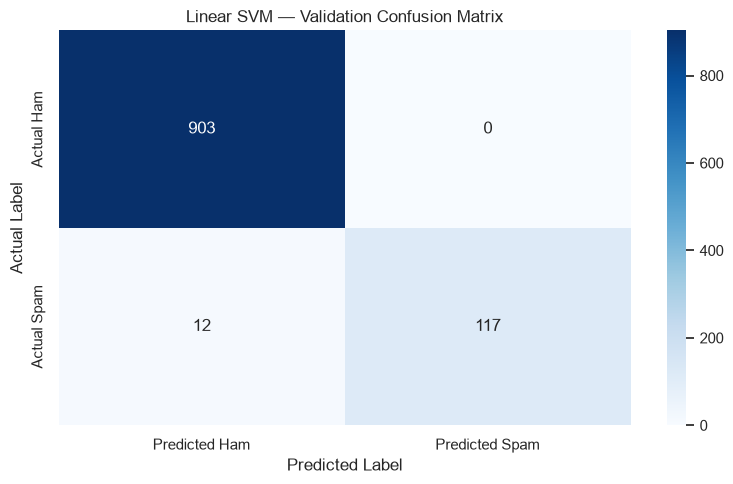

In [7]:
def calculate_metrics(y_true, predictions, scores):
    cm = confusion_matrix(y_true, predictions, labels=[0, 1])

    tn, fp, fn, tp = cm.ravel()

    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "ROC-AUC": roc_auc_score(y_true, scores),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }


linear_val_predictions = best_linear_model.predict(X_val)
linear_val_scores = best_linear_model.decision_function(X_val)

linear_val_metrics = calculate_metrics(
    y_val,
    linear_val_predictions,
    linear_val_scores
)                              

print("LINEAR SVM — VALIDATION METRICS")
print("-" * 40)

for metric, value in linear_val_metrics.items():
    print(
        f"{metric:15s}: "
        f"{value:.4f}" if isinstance(value, (float, np.floating))
        else f"{metric:15s}: {value}"
    )

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        linear_val_predictions,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

cm = confusion_matrix(
    y_val, linear_val_predictions, labels=[0, 1]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicted Ham", "Predicted Spam"],
    yticklabels=["Actual Ham", "Actual Spam"]
)

plt.title("Linear SVM — Validation Confusion Matrix")
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.tight_layout()
plt.show()


In [8]:

error_analysis = X_val[["message"]].copy()
error_analysis["Actual"] = y_val.map({0: "Ham", 1: "Spam"})
error_analysis["Predicted"] = pd.Series(
    linear_val_predictions, index=X_val.index
).map({0: "Ham", 1: "Spam"})

error_analysis["Error Type"] = np.select(
    [
        (error_analysis["Actual"] == "Ham") &
        (error_analysis["Predicted"] == "Spam"),

        (error_analysis["Actual"] == "Spam") &
        (error_analysis["Predicted"] == "Ham")
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

false_positives = error_analysis[
    error_analysis["Error Type"] == "False Positive"
]
 
false_negatives = error_analysis[
    error_analysis["Error Type"] == "False Negative"
]

print("FIVE FALSE POSITIVES")
print("=" * 60)

if len(false_positives):
    display(false_positives.head(5))
else:
    print("No false positives found in the validation set.")

print("\nFIVE FALSE NEGATIVES")
print("=" * 60)

if len(false_negatives):
    display(false_negatives.head(5))
else:
    print("No false negatives found in the validation set.")


FIVE FALSE POSITIVES
No false positives found in the validation set.

FIVE FALSE NEGATIVES


,message,Actual,Predicted,Error Type
222,Will u meet ur dream partner soon? Is ur caree...,Spam,Ham,False Negative
2814,"Do you ever notice that when you're driving, a...",Spam,Ham,False Negative
2156,Hi ya babe x u 4goten bout me?' scammers getti...,Spam,Ham,False Negative
932,Filthy stories and GIRLS waiting for your,Spam,Ham,False Negative
162,BangBabes Ur order is on the way. U SHOULD rec...,Spam,Ham,False Negative


In [9]:


rbf_pipeline = create_svm_pipeline(kernel="rbf")

param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1]
}

grid_search = GridSearchCV(
    estimator=rbf_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=1,
    return_train_score=True
)

start_time = time.perf_counter()

grid_search.fit(X_train, y_train)

grid_search_time = time.perf_counter() - start_time

print("\nGrid search completed.")
print("Grid search time:", round(grid_search_time, 2), "seconds")
print("Best parameters:", grid_search.best_params_)
print("Best mean CV F1-score:", round(grid_search.best_score_, 4))

grid_results = pd.DataFrame(grid_search.cv_results_)

display(
    grid_results[
        [
            "param_svm__C",
            "param_svm__gamma",
            "mean_test_score",
            "std_test_score",
            "mean_train_score",
            "rank_test_score"
        ]
    ].sort_values("rank_test_score").reset_index(drop=True)
)


Fitting 5 folds for each of 16 candidates, totalling 80 fits

Grid search completed.
Grid search time: 22.86 seconds
Best parameters: {'svm__C': 10, 'svm__gamma': 0.1}
Best mean CV F1-score: 0.9507


,param_svm__C,param_svm__gamma,mean_test_score,std_test_score,mean_train_score,rank_test_score
0,10.0,0.100,0.950748,0.010519,0.993788,1
1,100.0,0.100,0.949351,0.011430,0.999024,2
2,100.0,0.010,0.948038,0.010700,0.990166,3
3,10.0,0.010,0.917972,0.025052,0.934084,4
4,10.0,1.000,0.917840,0.027459,1.000000,5
5,100.0,1.000,0.917840,0.027459,1.000000,5
6,1.0,0.100,0.909111,0.024288,0.925727,7
7,1.0,1.000,0.908941,0.027811,0.985498,8
8,100.0,0.001,0.905850,0.023501,0.928707,9
9,10.0,0.001,0.858727,0.028183,0.859160,10


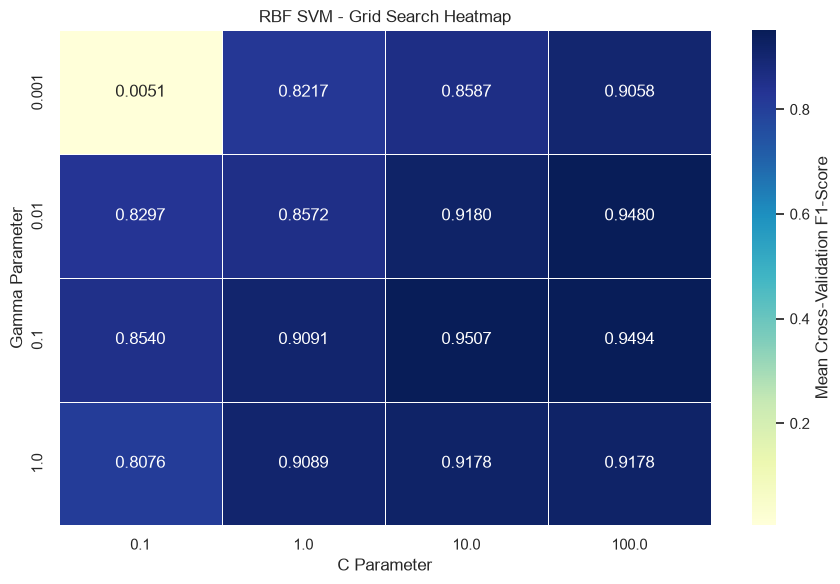

In [10]:
# Convert GridSearchCV results into a DataFrame
grid_results = pd.DataFrame(grid_search.cv_results_)

# Extract C, gamma and mean cross-validation F1-score
grid_results["C"] = grid_results["param_svm__C"].astype(float)
grid_results["Gamma"] = grid_results["param_svm__gamma"].astype(float)

# Create a matrix of F1-scores for the heatmap
heatmap_data = grid_results.pivot(
    index="Gamma",
    columns="C",
    values="mean_test_score"
)

# Plot the heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".4f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Mean Cross-Validation F1-Score"}
)

plt.title("RBF SVM - Grid Search Heatmap")
plt.xlabel("C Parameter")
plt.ylabel("Gamma Parameter")

plt.tight_layout()
plt.show()


In [11]:

final_linear_model = create_svm_pipeline(
    kernel="linear",
    C=best_linear_C
)

linear_start = time.perf_counter()
final_linear_model.fit(X_train_val, y_train_val)
linear_fit_time = time.perf_counter() - linear_start

# Final RBF SVM using GridSearchCV-selected parameters
best_rbf_C = grid_search.best_params_["svm__C"]
best_rbf_gamma = grid_search.best_params_["svm__gamma"]

final_rbf_model = create_svm_pipeline(
    kernel="rbf",
    C=best_rbf_C,
    gamma=best_rbf_gamma
)

rbf_start = time.perf_counter()
final_rbf_model.fit(X_train_val, y_train_val)
rbf_fit_time = time.perf_counter() - rbf_start

print("Final Linear SVM C:", best_linear_C)
print("Final RBF SVM C:", best_rbf_C)
print("Final RBF SVM gamma:", best_rbf_gamma)

print("\nLinear SVM fit time:", round(linear_fit_time, 3), "seconds")
print("RBF SVM fit time:", round(rbf_fit_time, 3), "seconds")


Final Linear SVM C: 1
Final RBF SVM C: 10
Final RBF SVM gamma: 0.1

Linear SVM fit time: 0.462 seconds
RBF SVM fit time: 0.383 seconds


FINAL HELD-OUT TEST COMPARISON


,Linear SVM,RBF SVM
Accuracy,0.9893,0.9913
Precision,0.9756,0.9837
Recall,0.9375,0.9453
F1-Score,0.9562,0.9641
Specificity,0.9967,0.9978
ROC-AUC,0.9971,0.9949
TN,901.0000,902.0000
FP,3.0000,2.0000
FN,8.0000,7.0000
TP,120.0000,121.0000



LINEAR SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.98      0.94      0.96       128

    accuracy                           0.99      1032
   macro avg       0.98      0.97      0.98      1032
weighted avg       0.99      0.99      0.99      1032


RBF SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.99      1.00      1.00       904
        Spam       0.98      0.95      0.96       128

    accuracy                           0.99      1032
   macro avg       0.99      0.97      0.98      1032
weighted avg       0.99      0.99      0.99      1032



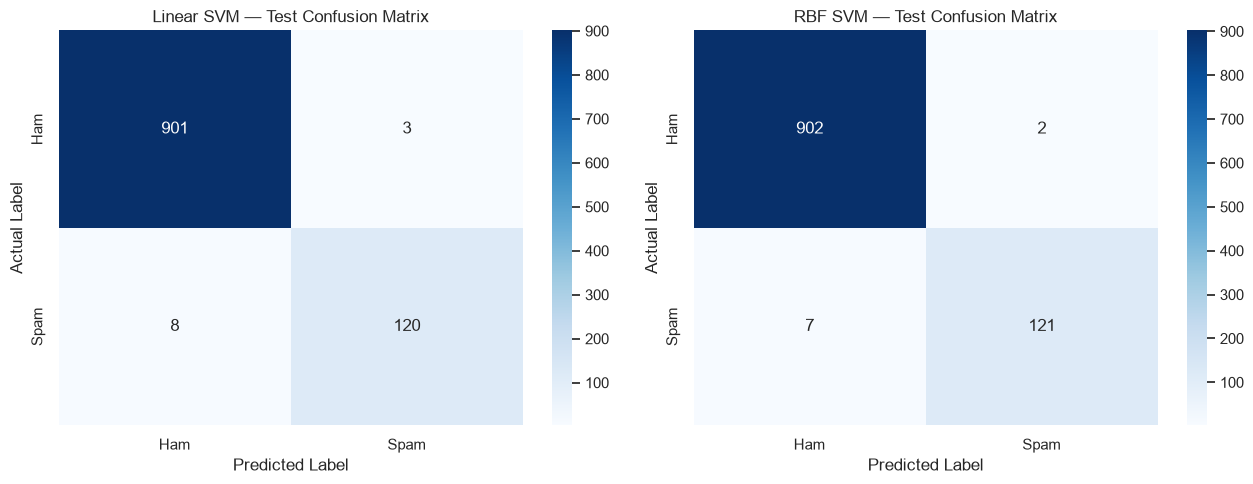

In [ ]:

def evaluate_model(model, X_data, y_true):
    start = time.perf_counter()
    predictions = model.predict(X_data)
    prediction_time = time.perf_counter() - start

    scores = model.decision_function(X_data)

    metrics = calculate_metrics(
        y_true,
        predictions,
        scores
    )

    metrics["Prediction Time (seconds)"] = prediction_time

    return predictions, scores, metrics

linear_test_pred, linear_test_scores, linear_test_metrics = (
    evaluate_model(final_linear_model, X_test, y_test)
)

rbf_test_pred, rbf_test_scores, rbf_test_metrics = (      
    evaluate_model(final_rbf_model, X_test, y_test)
)

comparison_df = pd.DataFrame(
    {
        "Linear SVM": linear_test_metrics,
        "RBF SVM": rbf_test_metrics
    }
)

print("FINAL HELD-OUT TEST COMPARISON")
display(comparison_df.round(4))

print("\nLINEAR SVM CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        linear_test_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

print("\nRBF SVM CLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        rbf_test_pred,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, predictions, title in [
    (axes[0], linear_test_pred, "Linear SVM"),
    (axes[1], rbf_test_pred, "RBF SVM")
]:
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Ham", "Spam"],
        yticklabels=["Ham", "Spam"],
        ax=ax
    )

    ax.set_title(f"{title} — Test Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()


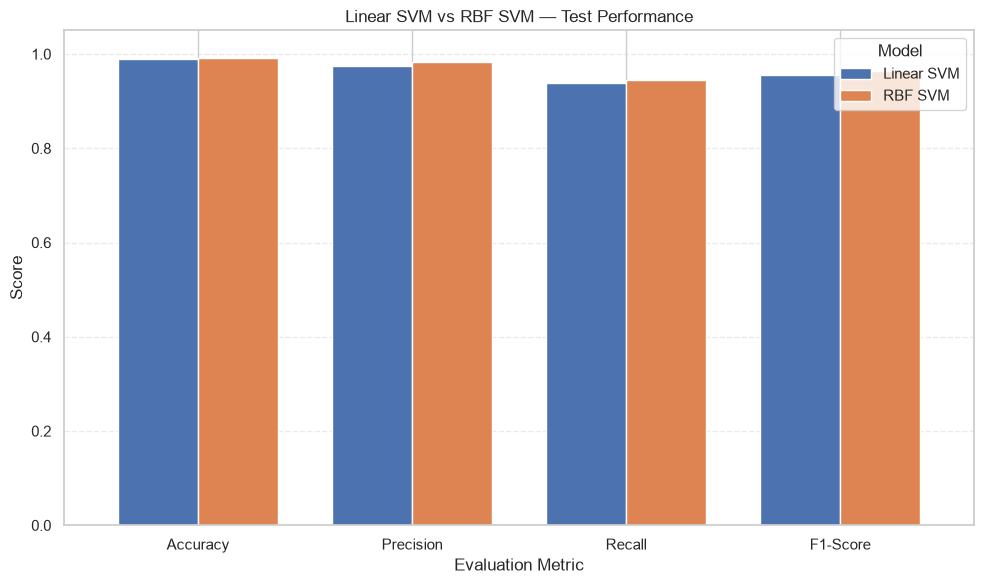

In [13]:
metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

comparison_plot = pd.DataFrame({
    "Metric": metrics_to_plot,
    "Linear SVM": [
        linear_test_metrics[m] for m in metrics_to_plot
    ],
    "RBF SVM": [
        rbf_test_metrics[m] for m in metrics_to_plot
    ]
})

plot_data = comparison_plot.set_index("Metric")

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

ax.set_title("Linear SVM vs RBF SVM — Test Performance")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


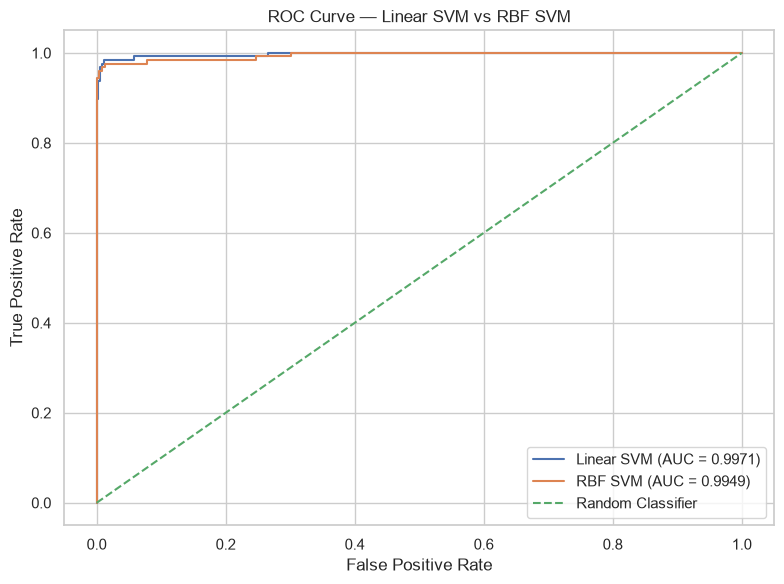

Linear SVM Test AUC: 0.9971
RBF SVM Test AUC: 0.9949


In [14]:


linear_fpr, linear_tpr, _ = roc_curve(
    y_test, linear_test_scores
)

rbf_fpr, rbf_tpr, _ = roc_curve(
    y_test, rbf_test_scores
)

linear_auc = roc_auc_score(y_test, linear_test_scores)
rbf_auc = roc_auc_score(y_test, rbf_test_scores)

plt.figure(figsize=(8, 6))

plt.plot(
    linear_fpr,
    linear_tpr,
    label=f"Linear SVM (AUC = {linear_auc:.4f})"
)

plt.plot(
    rbf_fpr,
    rbf_tpr,
    label=f"RBF SVM (AUC = {rbf_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Linear SVM vs RBF SVM")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Linear SVM Test AUC:", round(linear_auc, 4))
print("RBF SVM Test AUC:", round(rbf_auc, 4))


In [15]:

print("=" * 65)
print("PRODUCTION MODEL COMPARISON")
print("=" * 65)

for name, metrics, fit_time in [
    ("Linear SVM", linear_test_metrics, linear_fit_time),
    ("RBF SVM", rbf_test_metrics, rbf_fit_time)
]:
    print(f"\n{name}")
    print("-" * 30)
    print(f"Accuracy:       {metrics['Accuracy']:.4f}")
    print(f"Precision:      {metrics['Precision']:.4f}")
    print(f"Recall:         {metrics['Recall']:.4f}")
    print(f"F1-score:       {metrics['F1-Score']:.4f}")
    print(f"ROC-AUC:        {metrics['ROC-AUC']:.4f}")
    print(f"Training time:  {fit_time:.3f} seconds")
    print(
        "Prediction time:",
        f"{metrics['Prediction Time (seconds)']:.4f} seconds"
    )

f1_difference = (
    rbf_test_metrics["F1-Score"]
    - linear_test_metrics["F1-Score"]
)



if f1_difference > 0.01:
    print(
        "RBF SVM achieves a meaningfully higher test F1-score. "
        "Consider it if improved spam detection justifies its "
        "computational cost."
    )
elif f1_difference < -0.01:
    print(
        "Linear SVM achieves a meaningfully higher test F1-score. "
        "It is a strong candidate for production."
    )
else:
    print(
        "The test F1-scores are close. Prefer Linear SVM as the "
        "initial production candidate because it is generally "
        "faster to train on sparse text features and easier to "
        "interpret."
    )

print(
    "\nBefore deployment, verify latency, memory usage, false-positive "
    "costs, and performance on new messages."
)


PRODUCTION MODEL COMPARISON

Linear SVM
------------------------------
Accuracy:       0.9893
Precision:      0.9756
Recall:         0.9375
F1-score:       0.9562
ROC-AUC:        0.9971
Training time:  0.462 seconds
Prediction time: 0.0937 seconds

RBF SVM
------------------------------
Accuracy:       0.9913
Precision:      0.9837
Recall:         0.9453
F1-score:       0.9641
ROC-AUC:        0.9949
Training time:  0.383 seconds
Prediction time: 0.0943 seconds
The test F1-scores are close. Prefer Linear SVM as the initial production candidate because it is generally faster to train on sparse text features and easier to interpret.

Before deployment, verify latency, memory usage, false-positive costs, and performance on new messages.
